# 4. Regression - Predict Diameter

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.5f}'.format)

from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

Load pandas, regression models, metrics, cross-validation and joblib; create output folders. Numbers are shown as normal values (like 3,810,113.98854) instead of scientific notation (3.810114e+06).

## Read the data

In [2]:
data = pd.read_csv('regression.csv')
data.head()

,H,albedo,a,i,diameter
0,3.40000,0.09000,2.76917,10.59407,939.40000
1,4.20000,0.10100,2.77384,34.83293,545.00000
2,5.33000,0.21400,2.66829,12.99104,246.59600
3,3.00000,0.42280,2.36142,7.14177,525.40000
4,6.90000,0.27400,2.57404,5.36743,106.69900


Read the regression data (H, albedo, a, i, diameter) made in notebook 2.

In [3]:
data.shape

(131237, 5)

Confirm the number of asteroids with a known diameter.

In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
H,"131,237.00000",15.12349,1.38471,3.00000,14.40000,15.20000,16.00000,27.50000
albedo,"131,237.00000",0.13239,0.11131,0.00100,0.05300,0.07900,0.19500,1.00000
a,"131,237.00000",2.82795,1.52134,0.62621,2.55124,2.76043,3.09755,376.13330
i,"131,237.00000",10.06999,6.67854,0.02206,4.97818,9.13569,13.41346,170.33459
diameter,"131,237.00000",5.61721,9.58072,0.00800,2.85300,4.05900,5.86300,939.40000


Check the ranges of each column before modelling.

## Diameter is very right-skewed, so we predict log(diameter)

In [5]:
print('skew of diameter     :', round(data['diameter'].skew(), 2))
print('skew of log diameter :', round(np.log(data['diameter']).skew(), 2))

skew of diameter     : 25.51
skew of log diameter : 0.74


Show that diameter is very skewed and log fixes it, which is why we predict log(diameter).

## Remove outliers using Z-score on log diameter

In [6]:
z = np.abs(stats.zscore(np.log(data['diameter'])))
print('Outliers:', (z >= 3).sum())

data = data[z < 3].reset_index(drop=True)
data.shape

Outliers: 1912


(129325, 5)

Remove extreme sizes (Z-score >= 3) so a few giant or tiny asteroids do not dominate the errors.

## Transform features

In [7]:
def make_features(df):
    new = pd.DataFrame()
    new['H'] = df['H']
    new['albedo'] = np.log(df['albedo'])
    new['a'] = np.log1p(df['a'])
    new['i'] = df['i']
    return new

X = make_features(data)
y = np.log(data['diameter'])
X.head()

,H,albedo,a,i
0,10.50000,-1.88387,1.15514,0.93950
1,11.10000,-1.75446,1.27529,12.16186
2,10.20000,-1.41882,1.31396,0.86779
3,9.70000,-1.07002,1.28086,11.99350
4,9.30000,0.00000,1.28412,3.43586


Apply the same transforms (log of albedo and a) in one function so the app can repeat them.

## Train test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(103460, 4) (25865, 4)


Keep 20% unseen for testing so the score is honest.

## Models

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}

The three regression models to compare.

## MLflow setup

In [10]:
os.environ['GIT_PYTHON_REFRESH'] = 'quiet'
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('Diameter_Regression')

2026/11/20 17:51:07 INFO mlflow.tracking.fluent: Experiment with name 'Diameter_Regression' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:C:/Users/Chandrasekar A/Documents/Kiro/Planetary Defense '
 'Analytics/mlruns/2'), creation_time=1795177267874, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1795177267874, lifecycle_stage='active', name='Diameter_Regression', tags={}, trace_location=None, workspace='default'>

Set up MLflow so every run is recorded.

## Train, evaluate and log each model

In [11]:
results = []
trained = {}

for name, model in models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    # metrics in km (after converting back from log)
    y_test_km = np.exp(y_test)
    y_pred_km = np.exp(y_pred)
    r2_km = r2_score(y_test_km, y_pred_km)
    rmse_km = np.sqrt(mean_squared_error(y_test_km, y_pred_km))
    mae_km = mean_absolute_error(y_test_km, y_pred_km)

    row = {'Model': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae,
           'R2_km': r2_km, 'RMSE_km': rmse_km, 'MAE_km': mae_km}
    results.append(row)
    trained[name] = pipe

    with mlflow.start_run(run_name=name):
        mlflow.log_param('model', name)
        mlflow.log_params(model.get_params())
        mlflow.log_metric('r2', r2)
        mlflow.log_metric('rmse', rmse)
        mlflow.log_metric('mae', mae)
        mlflow.log_metric('r2_km', r2_km)
        mlflow.log_metric('rmse_km', rmse_km)
        mlflow.log_metric('mae_km', mae_km)
        mlflow.sklearn.log_model(pipe, name='model', serialization_format='cloudpickle')

    print(name, 'done')

2026/11/20 17:51:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Linear Regression done


2026/11/20 17:51:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest done


2026/11/20 17:51:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost done


Train each model, score it in log scale and in km, and log it to MLflow.

## Compare models (R2, RMSE, MAE on log scale; _km columns in km)

In [12]:
results_df = pd.DataFrame(results).round(4)
results_df.to_csv('results/regression_results.csv', index=False)
results_df

,Model,R2,RMSE,MAE,R2_km,RMSE_km,MAE_km
0,Linear Regression,0.95180,0.12200,0.08260,0.95750,0.69700,0.40210
1,Random Forest,0.96190,0.10840,0.07570,0.97010,0.58490,0.35770
2,XGBoost,0.96370,0.10580,0.07390,0.97130,0.57250,0.34910


Put the results of all 3 models in one table and save it.

## Plot R2 and RMSE

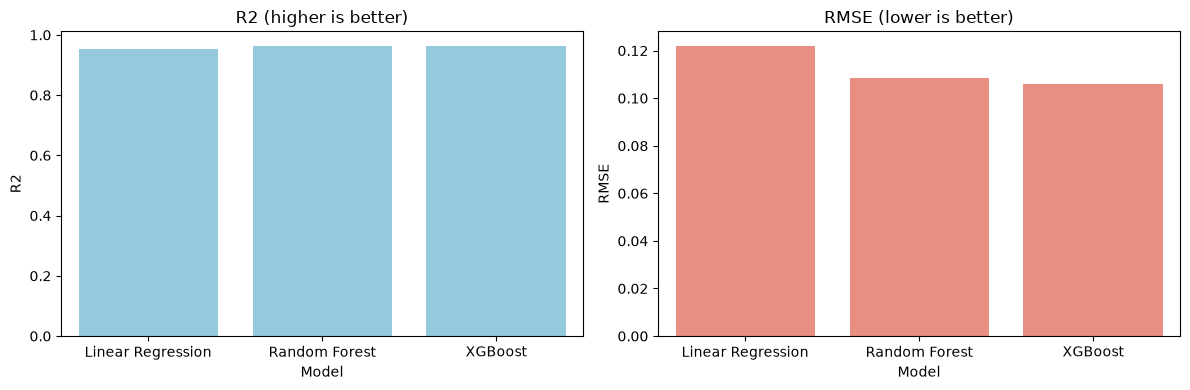

In [13]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.barplot(x=results_df['Model'], y=results_df['R2'], color='skyblue')
plt.title('R2 (higher is better)')

plt.subplot(1, 2, 2)
sns.barplot(x=results_df['Model'], y=results_df['RMSE'], color='salmon')
plt.title('RMSE (lower is better)')

plt.tight_layout()
plt.savefig('images/regression_comparison.png')
plt.show()

A chart makes R2 and RMSE easy to compare.

# Evaluation of all 3 models

## Actual vs predicted for all 3 models

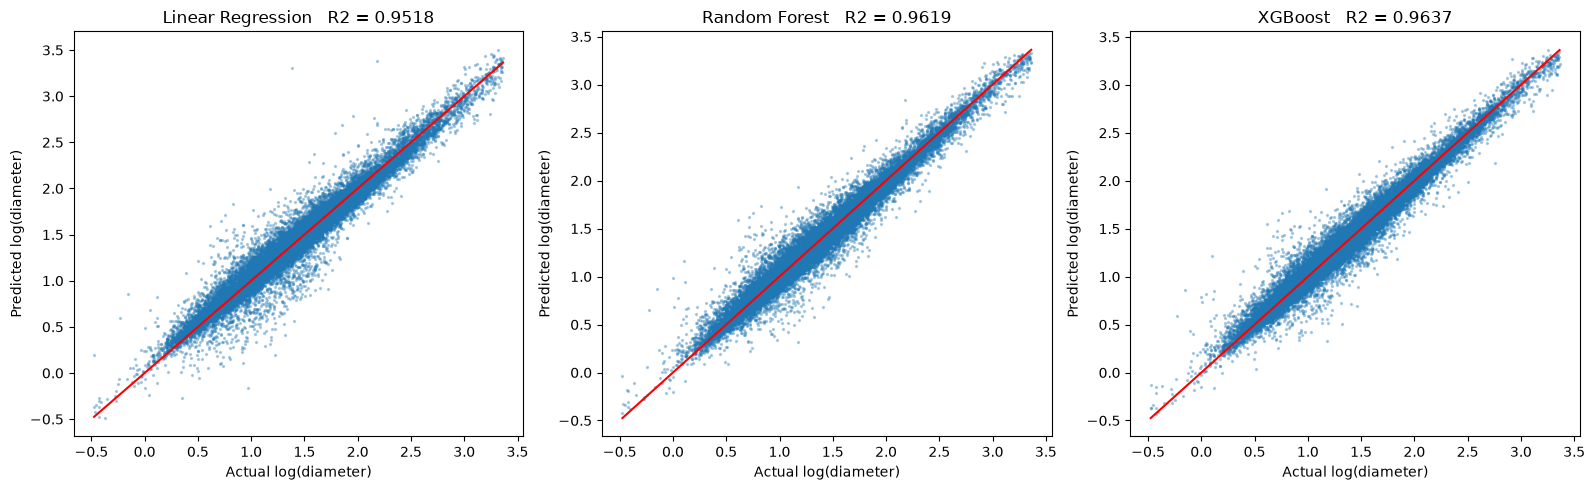

In [14]:
plt.figure(figsize=(16, 5))
n = 1
for name, pipe in trained.items():
    y_pred = pipe.predict(X_test)
    plt.subplot(1, 3, n)
    plt.scatter(y_test, y_pred, s=2, alpha=0.3)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
    plt.xlabel('Actual log(diameter)')
    plt.ylabel('Predicted log(diameter)')
    plt.title(name + '   R2 = ' + str(round(r2_score(y_test, y_pred), 4)))
    n = n + 1
plt.tight_layout()
plt.savefig('images/regression_actual_vs_pred_all.png')
plt.show()

Actual vs predicted plots show how close each model's predictions are to the truth.

## Residuals for all 3 models (narrow and centred on 0 is better)

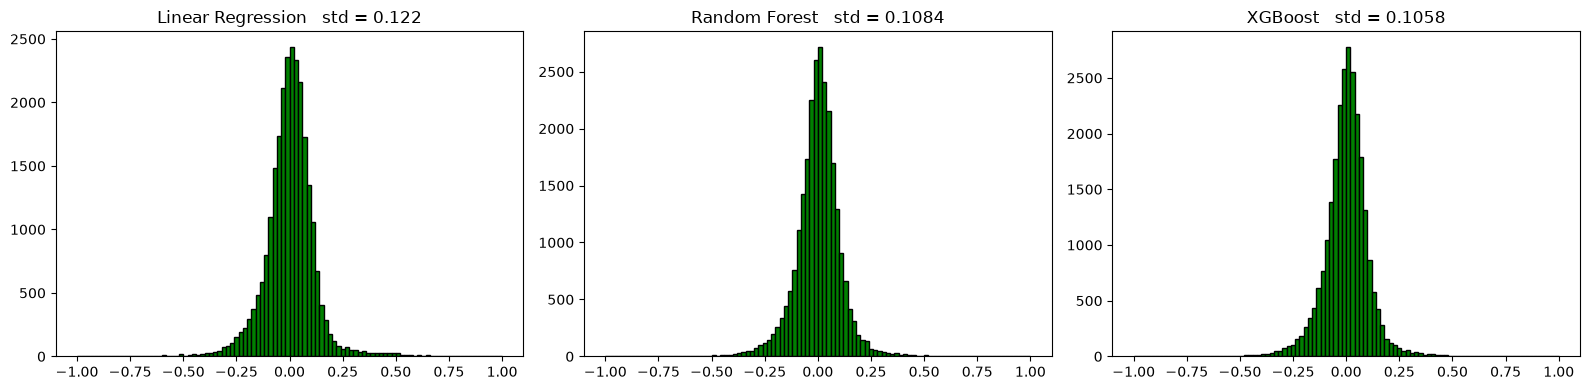

In [15]:
plt.figure(figsize=(16, 4))
n = 1
for name, pipe in trained.items():
    residuals = y_test - pipe.predict(X_test)
    plt.subplot(1, 3, n)
    plt.hist(residuals, bins=100, range=(-1, 1), color='green', edgecolor='black')
    plt.title(name + '   std = ' + str(round(residuals.std(), 4)))
    n = n + 1
plt.tight_layout()
plt.savefig('images/regression_residuals_all.png')
plt.show()

Residual plots show the size and spread of each model's errors.

## 5-fold cross validation for all 3 models

In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, pipe in trained.items():
    scores = cross_val_score(pipe, X, y, cv=kf, scoring='r2')
    cv_rows.append({'Model': name, 'CV_R2_mean': scores.mean(), 'CV_R2_std': scores.std()})
    print(name, ':', scores.round(4))

cv_df = pd.DataFrame(cv_rows).round(4)
cv_df.to_csv('results/regression_cv.csv', index=False)
cv_df

Linear Regression : [0.9518 0.9508 0.9521 0.9537 0.9531]


Random Forest : [0.9619 0.9599 0.9621 0.9626 0.9623]


XGBoost : [0.9639 0.9618 0.9637 0.9643 0.9641]


,Model,CV_R2_mean,CV_R2_std
0,Linear Regression,0.95230,0.00100
1,Random Forest,0.96180,0.00090
2,XGBoost,0.96360,0.00090


Cross-validation checks each model on 5 different splits so the result is not luck.

## Full evaluation table

In [17]:
eval_df = results_df.merge(cv_df, on='Model')
eval_df = eval_df.sort_values('R2', ascending=False).reset_index(drop=True)
eval_df['Rank'] = eval_df.index + 1
eval_df

,Model,R2,RMSE,MAE,R2_km,RMSE_km,MAE_km,CV_R2_mean,CV_R2_std,Rank
0,XGBoost,0.96370,0.10580,0.07390,0.97130,0.57250,0.34910,0.96360,0.00090,1
1,Random Forest,0.96190,0.10840,0.07570,0.97010,0.58490,0.35770,0.96180,0.00090,2
2,Linear Regression,0.95180,0.12200,0.08260,0.95750,0.69700,0.40210,0.95230,0.00100,3


One table with test and cross-validation scores for all 3 models.

## Pick the best model (highest test R2, check RMSE, MAE and CV agree)

In [18]:
best_name = eval_df.iloc[0]['Model']
best_model = trained[best_name]
print('Best model:', best_name)

Best model: XGBoost


Choose the model with the highest R2.

## Why this model is the best

In [19]:
best = eval_df.iloc[0]
print('Rule: highest R2 on test data. Lower RMSE and MAE and a stable CV score must agree.')
print()
for _, row in eval_df.iterrows():
    if row['Model'] == best_name:
        reason = 'SELECTED - highest R2, lowest RMSE and MAE, stable CV'
    else:
        reason = ('R2 lower by ' + str(round(best['R2'] - row['R2'], 4)) +
                  ', RMSE higher by ' + str(round(row['RMSE'] - best['RMSE'], 4)) +
                  ', MAE higher by ' + str(round(row['MAE'] - best['MAE'], 4)))
    print(str(row['Rank']) + '. ' + row['Model'].ljust(18), '->', reason)

Rule: highest R2 on test data. Lower RMSE and MAE and a stable CV score must agree.

1. XGBoost            -> SELECTED - highest R2, lowest RMSE and MAE, stable CV
2. Random Forest      -> R2 lower by 0.0018, RMSE higher by 0.0026, MAE higher by 0.0018
3. Linear Regression  -> R2 lower by 0.0119, RMSE higher by 0.0162, MAE higher by 0.0087


Print why each model was selected or rejected.

## Actual vs predicted (best model)

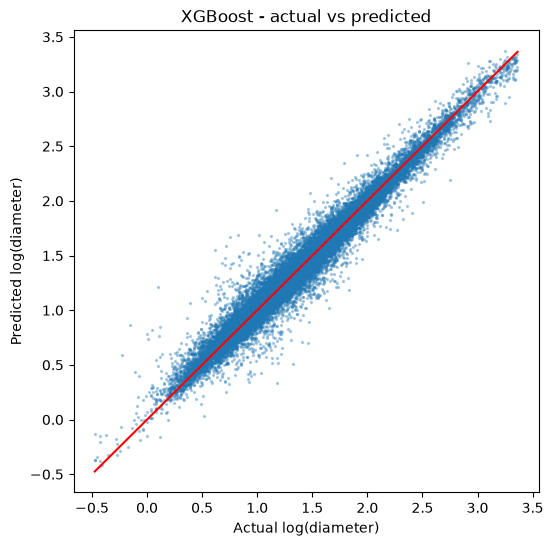

In [20]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=2, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual log(diameter)')
plt.ylabel('Predicted log(diameter)')
plt.title(best_name + ' - actual vs predicted')
plt.savefig('images/regression_actual_vs_pred.png')
plt.show()

Actual vs predicted for the chosen model.

## Residuals

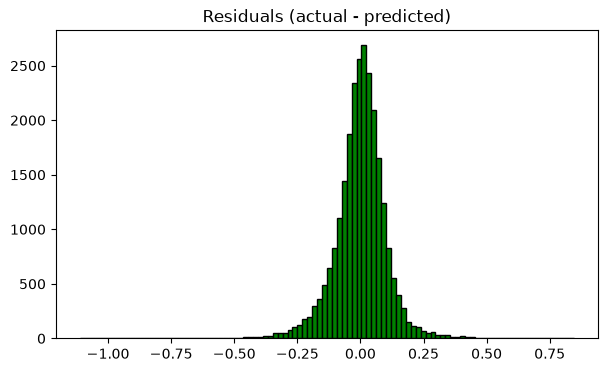

In [21]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=100, color='green', edgecolor='black')
plt.title('Residuals (actual - predicted)')
plt.savefig('images/regression_residuals.png')
plt.show()

Residuals of the chosen model; centred on 0 means no bias.

## Save the best model

In [22]:
joblib.dump(best_model, 'models/diameter_model.pkl')
print('Saved', best_name)

Saved XGBoost


Save the best model so the app can use it.

# SHAP - explain the best model

In [23]:
import shap

shap_sample = X_test.sample(1000, random_state=42)
shap_scaled = pd.DataFrame(best_model.named_steps['scaler'].transform(shap_sample), columns=X.columns)

model_only = best_model.named_steps['model']
if best_name == 'Linear Regression':
    explainer = shap.LinearExplainer(model_only, shap_scaled)
else:
    explainer = shap.TreeExplainer(model_only)

shap_values = explainer(shap_scaled)

Set up SHAP to explain the diameter model.

## SHAP summary plot

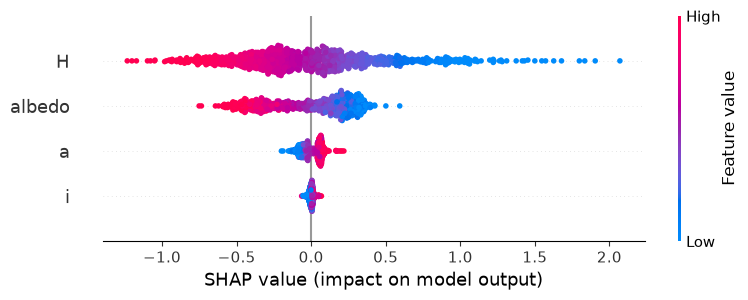

In [24]:
shap.summary_plot(shap_values, shap_scaled, show=False)
plt.tight_layout()
plt.savefig('images/shap_summary_diameter.png')
plt.show()

Summary plot shows which features drive the size predictions.

## SHAP feature importance (bar)

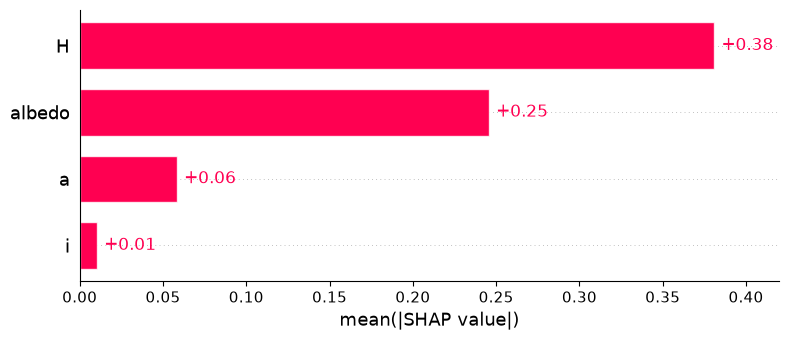

In [25]:
shap.plots.bar(shap_values, show=False)
plt.tight_layout()
plt.savefig('images/shap_bar_diameter.png')
plt.show()

Bar plot shows overall feature importance.

## SHAP waterfall for one asteroid

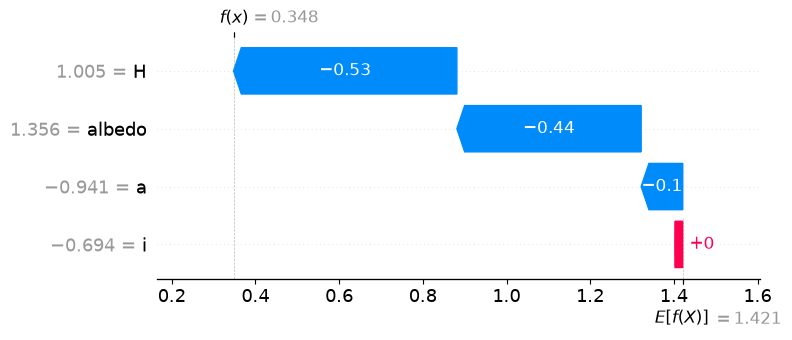

In [26]:
shap.plots.waterfall(shap_values[0], show=False)
plt.tight_layout()
plt.savefig('images/shap_waterfall_diameter.png')
plt.show()

Waterfall shows how each feature built one asteroid's predicted size.